In [1]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles:")
print(os.listdir())

Current folder:
C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison

Files:
['.ipynb_checkpoints', 'cleaned_student_performance.csv', 'Level_3_Task_1_Feature_Engineering_Model_Comparison.ipynb']


In [2]:
import pandas as pd
import numpy as np

# Load the cleaned student performance dataset
df = pd.read_csv("cleaned_student_performance.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (2392, 15)

Column names:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']

First 5 rows:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4


In [3]:
# Create a copy for Level 3 Task 1
ml_df = df.copy()

# Create a new engineered feature
ml_df["AcademicSupport"] = (
    ml_df["Tutoring"] + ml_df["ParentalSupport"]
)

# Select 4 useful input features
features = [
    "StudyTimeWeekly",
    "Absences",
    "AcademicSupport",
    "Age"
]

target = "GPA"

print("Selected features:", features)
print("Target variable:", target)

print("\nDataset after feature engineering:")
display(ml_df[features + [target]].head())

print("\nMissing values:")
print(ml_df[features + [target]].isnull().sum())

Selected features: ['StudyTimeWeekly', 'Absences', 'AcademicSupport', 'Age']
Target variable: GPA

Dataset after feature engineering:


,StudyTimeWeekly,Absences,AcademicSupport,Age,GPA
0,19.833723,7,3,17,2.929196
1,15.408756,0,1,18,3.042915
2,4.210570,26,2,15,0.112602
3,10.028829,14,3,17,2.054218
4,4.672495,17,4,17,1.288061



Missing values:
StudyTimeWeekly    0
Absences           0
AcademicSupport    0
Age                0
GPA                0
dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

# Input features and target
X = ml_df[features]
y = ml_df[target]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training input shape: (1913, 4)
Testing input shape: (479, 4)
Training target shape: (1913,)
Testing target shape: (479,)


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline prediction: average GPA from training data
baseline_prediction = np.full(
    len(y_test), y_train.mean()
)

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))
baseline_r2 = r2_score(y_test, baseline_prediction)

print("BASELINE MODEL RESULTS")
print("----------------------")
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²:   {baseline_r2:.4f}")

BASELINE MODEL RESULTS
----------------------
MAE:  0.7660
RMSE: 0.9097
R²:   -0.0008


In [8]:
from sklearn.linear_model import LinearRegression

# Create and train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict GPA for the testing data
linear_prediction = linear_model.predict(X_test)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_prediction)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_prediction))
linear_r2 = r2_score(y_test, linear_prediction)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print(f"MAE:  {linear_mae:.4f}")
print(f"RMSE: {linear_rmse:.4f}")
print(f"R²:   {linear_r2:.4f}")

LINEAR REGRESSION RESULTS
-------------------------
MAE:  0.1876
RMSE: 0.2426
R²:   0.9288


In [9]:
from sklearn.ensemble import RandomForestRegressor

# Create and train the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict GPA for the testing data
rf_prediction = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_prediction)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_prediction))
rf_r2 = r2_score(y_test, rf_prediction)

print("RANDOM FOREST RESULTS")
print("---------------------")
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")


RANDOM FOREST RESULTS
---------------------
MAE:  0.2087
RMSE: 0.2636
R²:   0.9160


In [11]:
# Compare all three models using the same test data
comparison_df = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R2 Score": [
        baseline_r2,
        linear_r2,
        rf_r2
    ]
})

comparison_df = comparison_df.round(4)

display(comparison_df)

,Model,MAE,RMSE,R2 Score
0,Baseline,0.7660,0.9097,-0.0008
1,Linear Regression,0.1876,0.2426,0.9288
2,Random Forest,0.2087,0.2636,0.9160


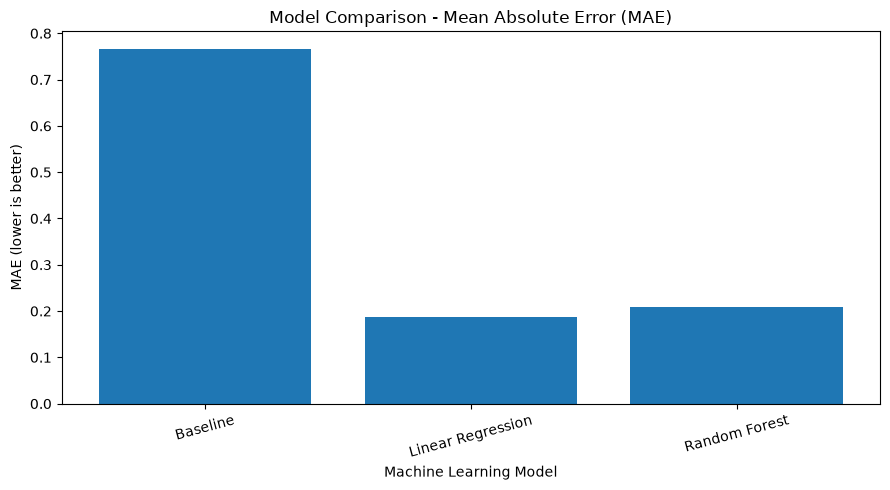

In [12]:
import matplotlib.pyplot as plt

# Plot MAE comparison
plt.figure(figsize=(9, 5))

plt.bar(comparison_df["Model"], comparison_df["MAE"])

plt.title("Model Comparison - Mean Absolute Error (MAE)")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

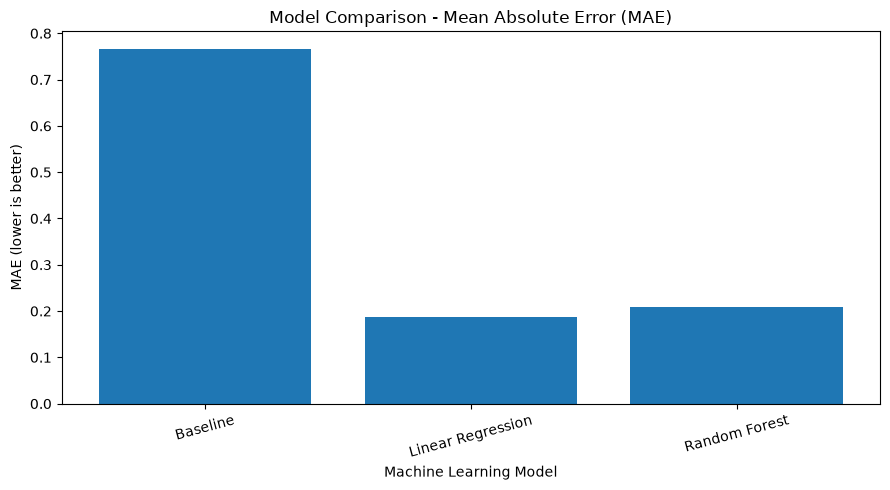

Chart saved: charts/model_comparison_mae.png
Results saved: model_comparison_results.csv


In [13]:
import os

# Create a folder for project charts
os.makedirs("charts", exist_ok=True)

# Save the model comparison chart
plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["MAE"])
plt.title("Model Comparison - Mean Absolute Error (MAE)")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("charts/model_comparison_mae.png", dpi=300, bbox_inches="tight")
plt.show()

# Save model comparison results
comparison_df.to_csv("model_comparison_results.csv", index=False)

print("Chart saved: charts/model_comparison_mae.png")
print("Results saved: model_comparison_results.csv")

In [14]:
# Find the model with the lowest MAE
model_results = comparison_df[
    comparison_df["Model"] != "Baseline"
]

best_model_name = model_results.loc[
    model_results["MAE"].idxmin(), "Model"
]

best_mae = model_results["MAE"].min()

print("BEST MODEL:", best_model_name)
print(f"Lowest MAE: {best_mae:.4f}")

print("\nMODEL COMPARISON")
display(comparison_df)

BEST MODEL: Linear Regression
Lowest MAE: 0.1876

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Baseline,0.7660,0.9097,-0.0008
1,Linear Regression,0.1876,0.2426,0.9288
2,Random Forest,0.2087,0.2636,0.9160


### Model Comparison and Conclusion

The objective of this project was to predict student GPA using selected academic and support-related features. A new feature named `AcademicSupport` was created by combining tutoring and parental support.

Three approaches were evaluated using the same 80:20 training and testing split: a baseline model, Linear Regression, and Random Forest Regression.

The baseline model achieved an MAE of 0.7660 and an R² score of -0.0008. Linear Regression achieved an MAE of 0.1876, RMSE of 0.2426, and R² score of 0.9288. Random Forest achieved an MAE of 0.2087, RMSE of 0.2636, and R² score of 0.9160.

**Linear Regression was selected as the best model** because it produced the lowest prediction errors and the highest R² score among the tested models.

This project demonstrates how feature engineering and model comparison can help select a suitable regression model. However, these results do not prove that the selected features cause changes in GPA. The model should be tested on additional data before real-world use.

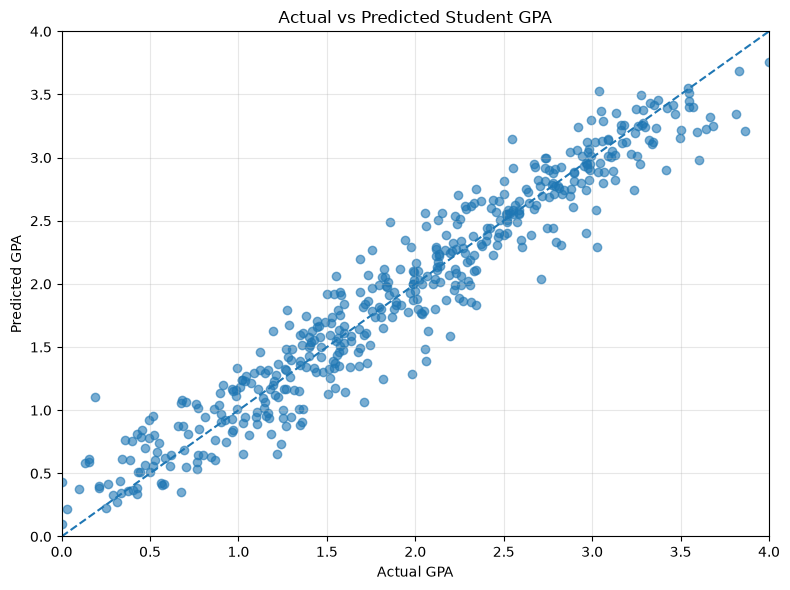

Chart saved: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison\charts\actual_vs_predicted_gpa.png


In [15]:
import os
import matplotlib.pyplot as plt

# Create charts folder if it doesn't exist
os.makedirs("charts", exist_ok=True)

# Plot actual vs predicted GPA
plt.figure(figsize=(8, 6))

plt.scatter(y_test, linear_prediction, alpha=0.6)
plt.plot([0, 4], [0, 4], linestyle="--")

plt.title("Actual vs Predicted Student GPA")
plt.xlabel("Actual GPA")
plt.ylabel("Predicted GPA")
plt.xlim(0, 4)
plt.ylim(0, 4)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig("charts/actual_vs_predicted_gpa.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", os.path.abspath("charts/actual_vs_predicted_gpa.png"))

# Level 3 Task 1: Feature Engineering and Model Comparison

## 1. Project Overview
This project predicts student Grade Point Average (GPA) using academic and student-support information. It demonstrates feature engineering, regression modelling, model evaluation, and comparison.

## 2. Dataset
- **Dataset:** Student Performance Dataset
- **Rows:** 2,392
- **Columns in original cleaned dataset:** 15
- **Target variable:** GPA
- **Data file:** `cleaned_student_performance.csv`

## 3. Tools and Libraries
- Python
- Jupyter Notebook
- pandas and NumPy
- Matplotlib
- scikit-learn

## 4. Feature Engineering
A new feature, `AcademicSupport`, was created by adding `Tutoring` and `ParentalSupport`.

The four model input features were:
- `StudyTimeWeekly`
- `Absences`
- `AcademicSupport`
- `Age`

The target variable was `GPA`. `GradeClass` was excluded to avoid using a grade category derived from GPA as a predictor.

## 5. Methodology
1. Loaded and inspected the cleaned dataset.
2. Created the engineered feature.
3. Split the data into 80% training and 20% testing data.
4. Used `random_state=42` for a consistent comparison.
5. Evaluated a mean-GPA baseline, Linear Regression, and Random Forest Regression.
6. Compared the models using MAE, RMSE, and R².
7. Created visualisations of model performance.

## 6. Model Results

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Baseline | 0.7660 | 0.9097 | -0.0008 |
| Linear Regression | 0.1876 | 0.2426 | 0.9288 |
| Random Forest | 0.2087 | 0.2636 | 0.9160 |

## 7. Conclusion
Linear Regression performed best among the tested models, with the lowest MAE and RMSE and the highest R². The model explained approximately 92.88% of the variation in GPA on the test set.

These results apply to this dataset and test split. They do not establish causal relationships, and further testing on additional data would be needed before real-world use.

## 8. Project Files
- `Level_3_Task_1_Feature_Engineering_Model_Comparison.ipynb` — analysis and modelling code
- `cleaned_student_performance.csv` — input dataset
- `model_comparison_results.csv` — model comparison table
- `charts/model_comparison_mae.png` — model error comparison chart
- `charts/actual_vs_predicted_gpa.png` — actual versus predicted GPA chart

In [16]:
import os

print("Current folder:", os.getcwd())

chart_path = os.path.abspath("charts/actual_vs_predicted_gpa.png")
print("Chart path:", chart_path)
print("Chart exists:", os.path.exists(chart_path))

Current folder: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison
Chart path: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison\charts\actual_vs_predicted_gpa.png
Chart exists: True


In [17]:
import os

print(os.path.abspath("charts"))

C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison\charts
